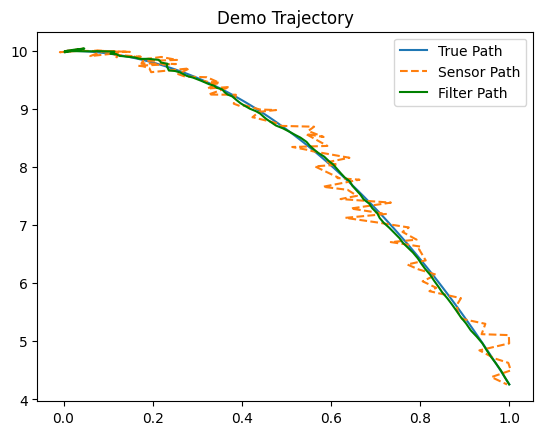

RMSE of filter: [0.02035638]
RMSE of sensor: [0.04467566]


In [189]:
import numpy as np
import matplotlib.pyplot as plt

class KalmanFilter:
    def __init__(self, dim_x, dim_z, dim_u = 0):
        """
        The following are place holder objects and must be defined appropriately after calling the class.
        dim_x is the dimension of the state vector
        dim_z is the dimension of the measurement
        dim_u is the dimension of the driving force
        """
        self.x = np.zeros((dim_x, 1))       #State
        self.P = np.eye(dim_x)              #Error Covariance Matrix
        self.Q = np.eye(dim_x)              #Process Variance
        self.R = np.eye(dim_z)              #Measurement Variance
        self.u = np.zeros((dim_u, 1))       #Driving Force
        self.B = np.zeros((dim_x, dim_u))   #Control Transition Matrix
        self.F = np.zeros((dim_x, dim_x))   #State Transition Matrix
        self.H = np.zeros((dim_z, dim_x))   #Measurement Function
        self._I = np.eye(dim_x)             #Identity Matrix
        self.K = np.zeros((dim_x, dim_z))   #Kalman Gain
        self.dim_z = dim_z

    def predict(self):
        """
        Filter produces an a priori estimate of the next position off of the current estimate.
        """
        self.x = (self.F @ self.x) + (self.B @ self.u)
        self.P = (self.F @ self.P @ self.F.T) + self.Q

    def update(self, z):
        """
        Filter produces an a posteriori estimate by combining the a priori estimate with an observation.
        z - observation
        """
        z = np.asarray(z).reshape(self.dim_z, 1)
        self.K = self.P @ self.H.T @ np.linalg.inv(self.H @ self.P @ self.H.T + self.R)
        self.x = self.x + self.K @ (z - self.H @ self.x)
        self.P = (self._I - self.K @ self.H) @ self.P @ (self._I - self.K @ self.H).T + (self.K @ self.R @ self.K.T)

#Sensor object taking in a true position and adding white noise.
class Sensor:
    def __init__(self, measure_variance):
        self.r = measure_variance

    def sense(self, x):
        return x + np.random.normal(0, np.sqrt(self.r), size = x.shape)

class falling_object:
    def __init__(self, initial_conditions, g, F):
        self.g = g
        self.x = initial_conditions
        self.F = F

    def move(self):
        self.x = self.F @ self.x
        self.x += np.array([[0],[0], [0], [0], [np.random.normal(0, np.sqrt(process_variance))]])

#Inital conditions
h = 0.01
max_steps = 100
process_variance = 0.1
measure_variance = 0.001
g = -9.8                                        #Acceleration due to gravity, up is positive
Tran_Matrix = np.array([[1, 0, h, 0, 0],        #State Transition Matrix
                 [0, 1, 0, h, 0],
                 [0, 0, 1, 0, 0],
                 [0, 0, 0, 1, h],
                 [0,0,0,0,1]])

starting_state = np.array([[0],[10],[1],[0], [g]])        #x, y, vx, vy
sensor = Sensor(measure_variance)
kf = KalmanFilter(5, 2, 0)

#Reset the object and filter before every simulation
def setup():
    kf.x = starting_state
    kf.P = np.eye(5) * 500
    kf.Q = np.array([[0,0,0,0,0],
                    [0,0,0,0,0],
                    [0,0,0,0,0],
                    [0,0,0,0,0],
                    [0,0,0,0,1]]) * process_variance
    kf.R = np.eye(2) * measure_variance
    kf.F = Tran_Matrix


    kf.H = np.array([[1,0,0,0,0],         #Picks out only x position and y position of the state vector
                    [0,1,0,0,0]])
    return falling_object(starting_state, g, Tran_Matrix)

#Run a simulation to produce a trajectory plot
x_true, y_true = [], []
x_sens, y_sens = [], []
x_filt, y_filt = [], []

obj = setup()
for i in range(max_steps):
    obj.move()
    sense = sensor.sense(obj.x)
    kf.predict()
    kf.update(np.array([sense[0], sense[1]]))

    x_true.append(obj.x[0,0])
    y_true.append(obj.x[1,0])
    x_sens.append(sense[0])
    y_sens.append(sense[1])
    x_filt.append(kf.x[0])
    y_filt.append(kf.x[1])


plt.plot(x_true, y_true, label='True Path')
plt.plot(x_sens, y_sens, label='Sensor Path', ls = '--')
plt.plot(x_filt, y_filt, label = 'Filter Path', color = 'g')
plt.legend()
plt.title("Demo Trajectory")
plt.show()


def rsme(xt, yt, xe, ye):
    dx = abs(xe - xt)
    dy = abs(ye - yt)
    return dx**2 + dy**2

N = 2000
filter_residual_sum = 0
sensor_residual_sum = 0
for j in range(N):
    filter_residual = 0
    sensor_residual = 0
    obj = setup()
    for i in range(max_steps):
        obj.move()
        sense = sensor.sense(obj.x)
        kf.predict()
        kf.update(np.array([sense[0], sense[1]]))
        filter_residual += rsme(obj.x[0], obj.x[1], kf.x[0], kf.x[1])
        sensor_residual += rsme(obj.x[0], obj.x[1], sense[0], sense[1])
    filter_residual_sum += filter_residual
    sensor_residual_sum += sensor_residual

filter_RMSE = np.sqrt(filter_residual_sum / (N * max_steps))
sensor_RMSE = np.sqrt(sensor_residual_sum / (N * max_steps))

print(f"RMSE of filter: {filter_RMSE}")
print(f"RMSE of sensor: {sensor_RMSE}")
